In [1]:
import sys, os
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# Dependence, regimes, and Bayesian extreme co-crashes

In [2]:
from src.dependence_and_tests import step9, step10, step11
display(step9())

,Pair,Pearson rho,Pearson low,Pearson high,Pearson Fisher-z low,Pearson Fisher-z high,Pearson Fisher-z width,Kendall tau,Kendall low,Kendall high
0,DBS-OCBC,0.778430,0.752599,0.802542,0.763294,0.792712,0.029418,0.544910,0.525671,0.563658
1,DBS-UOB,0.758815,0.732311,0.783889,0.742533,0.774201,0.031668,0.530101,0.511212,0.548553
2,OCBC-UOB,0.776025,0.748233,0.801628,0.760747,0.790444,0.029697,0.542558,0.523491,0.561113


Pearson Fisher-z intervals are typically narrower (~0.03) than Pearson bootstrap intervals (~0.05) because joint heavy tails inflate correlation variability beyond Normal theory.

In [3]:
permutations, chisq = step10()
display(permutations); display(chisq)

,Bank,Comparison,Calm N,Stress N,Observed ratio,Two-sided empirical p,One-sided stress>calm p
0,DBS,Calm vs COVID,754,103,2.223054,0.000100,0.000100
1,DBS,Calm vs Rate Hike,754,499,0.943500,0.286871,0.856114
2,OCBC,Calm vs COVID,754,103,2.229882,0.000100,0.000100
3,OCBC,Calm vs Rate Hike,754,499,0.864694,0.014299,0.993401
4,UOB,Calm vs COVID,754,103,2.222365,0.000100,0.000100
5,UOB,Calm vs Rate Hike,754,499,0.994688,0.925807,0.528247


,Pair,00,01,10,11,Minimum expected count,All expected >= 5,Chi-square,p-value,Degrees of freedom
0,DBS-OCBC,2356,129,129,148,27.780232,True,642.703214,8.630423e-142,1
1,DBS-UOB,2363,122,122,155,27.780232,True,719.727172,1.534565e-158,1
2,OCBC-UOB,2373,112,112,165,27.780232,True,837.321151,4.149533e-184,1


COVID dispersion increases sharply for every bank (p<0.0001). OCBC rate-hike dispersion is lower than calm (ratio 0.86), and its p=0.0143 does not survive Bonferroni correction across six tests.

In [4]:
bayesian = step11()
display(bayesian)

,Pair A,Pair B,n_extreme_A,k_joint,Observed proportion,Wald low,Wald high,Bootstrap low,Bootstrap high,Beta flat low,Beta flat high,Skeptical low,Skeptical high,Jeffreys low,Jeffreys high
0,DBS,OCBC,277,148,0.534296,0.475553,0.593039,0.476534,0.592058,0.475435,0.592203,0.448293,0.561744,0.475452,0.592428
1,DBS,UOB,277,155,0.559567,0.501105,0.618029,0.501805,0.617329,0.500629,0.616847,0.471802,0.585072,0.500738,0.617158
2,OCBC,UOB,277,165,0.595668,0.537874,0.653461,0.537906,0.653430,0.536885,0.651789,0.505607,0.618178,0.537127,0.652221


The three unordered pairs show strong worst-10% clustering. Flat/Jeffreys priors are close to frequentist intervals, while Beta(2,18) illustrates prior sensitivity.

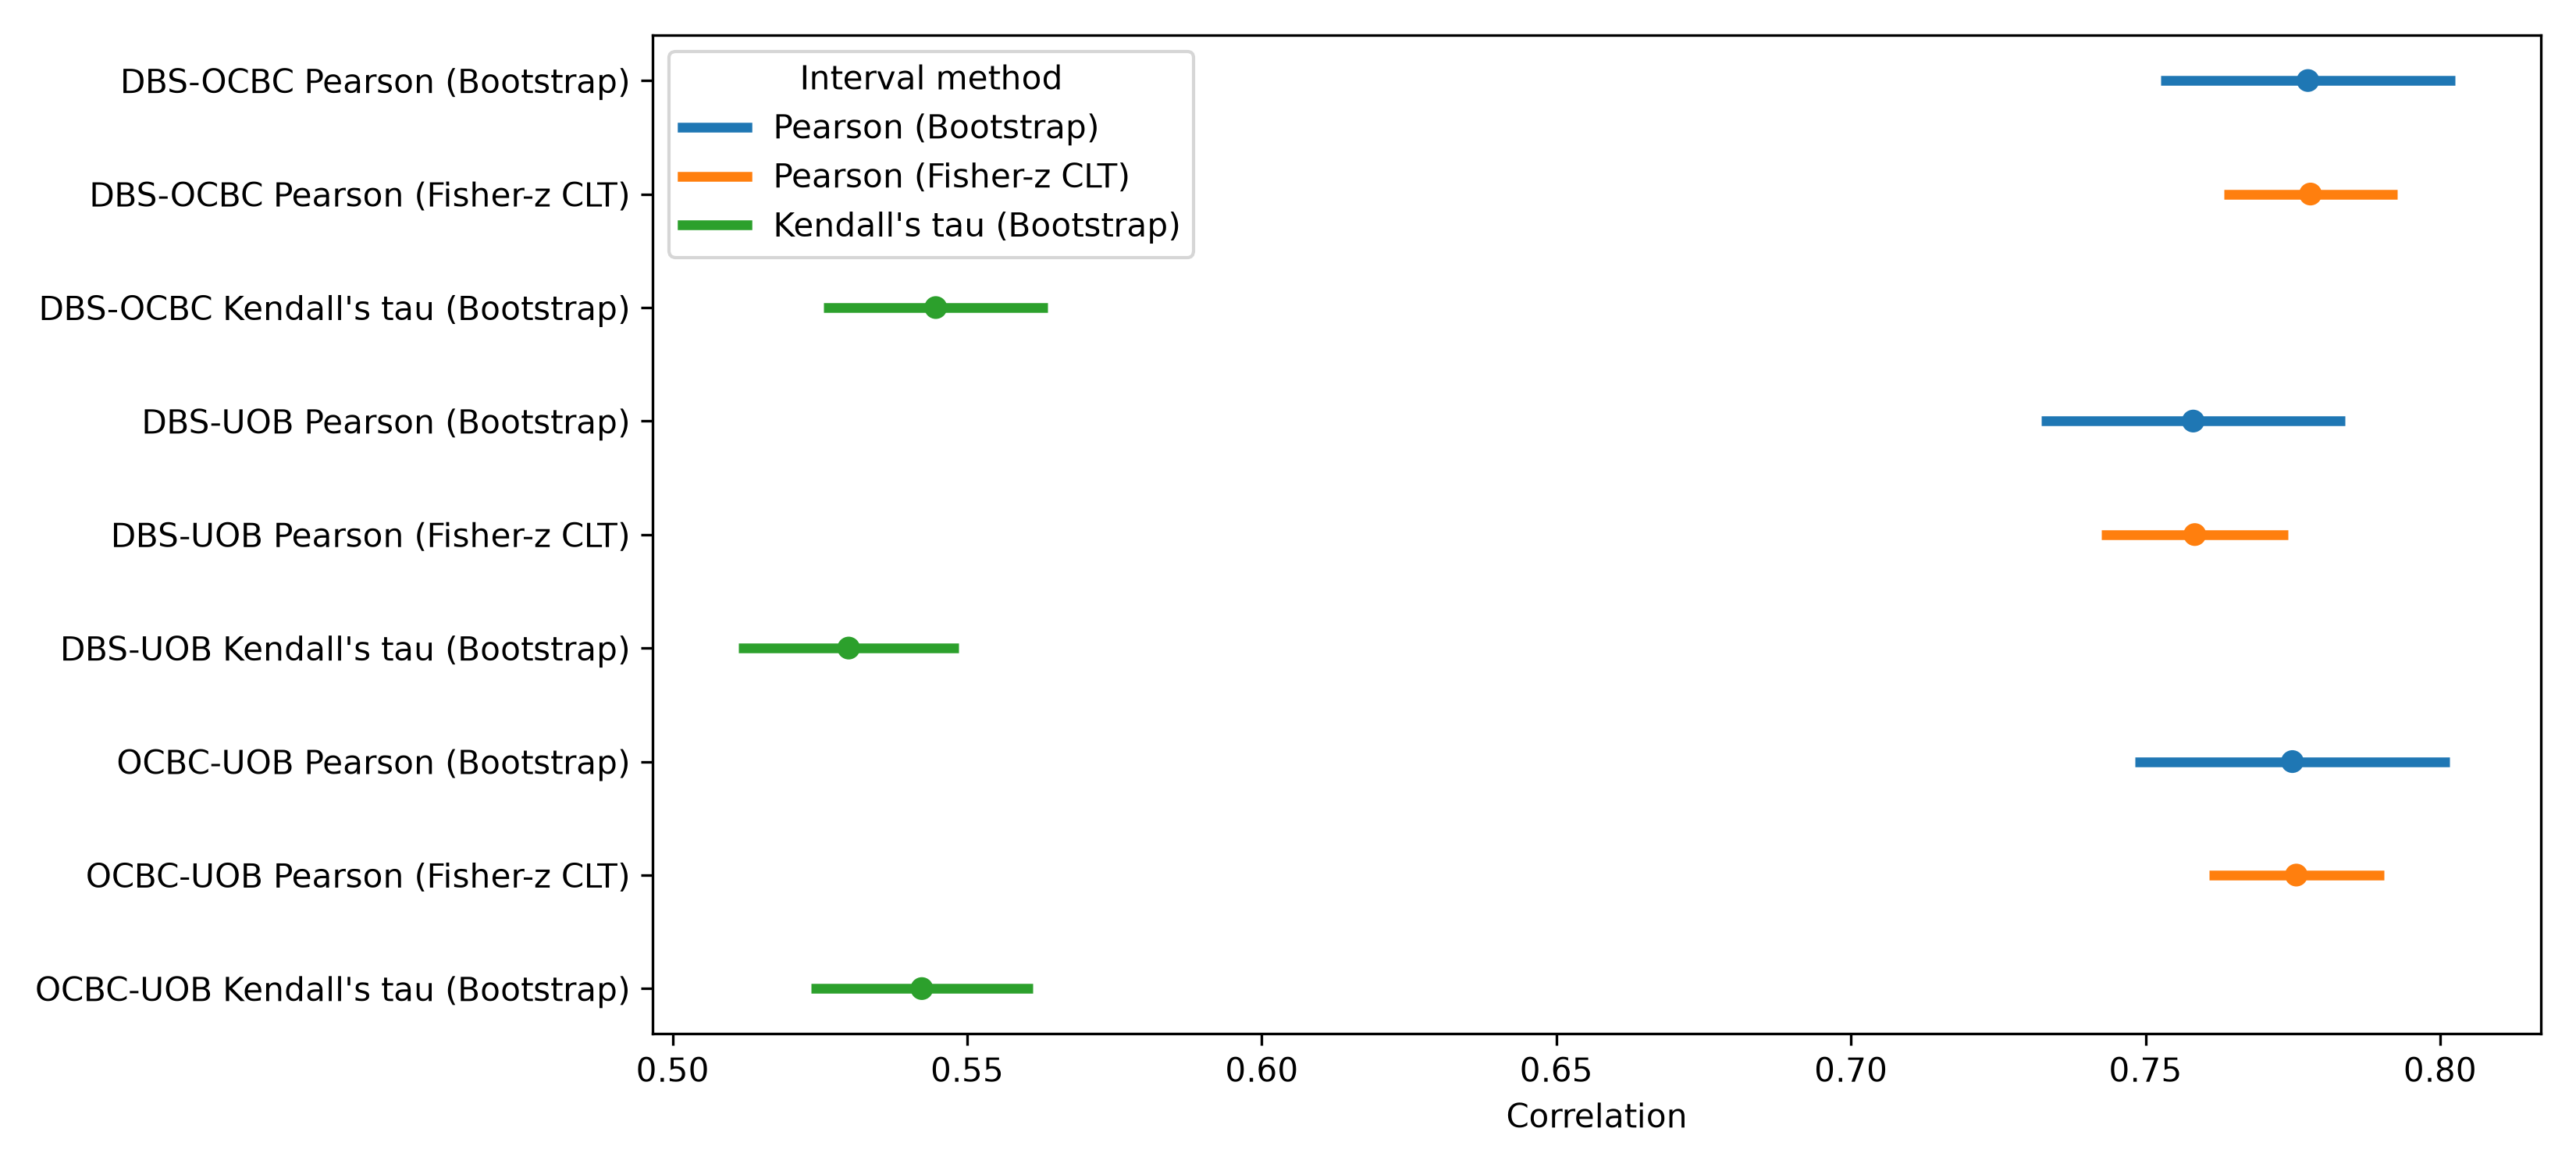

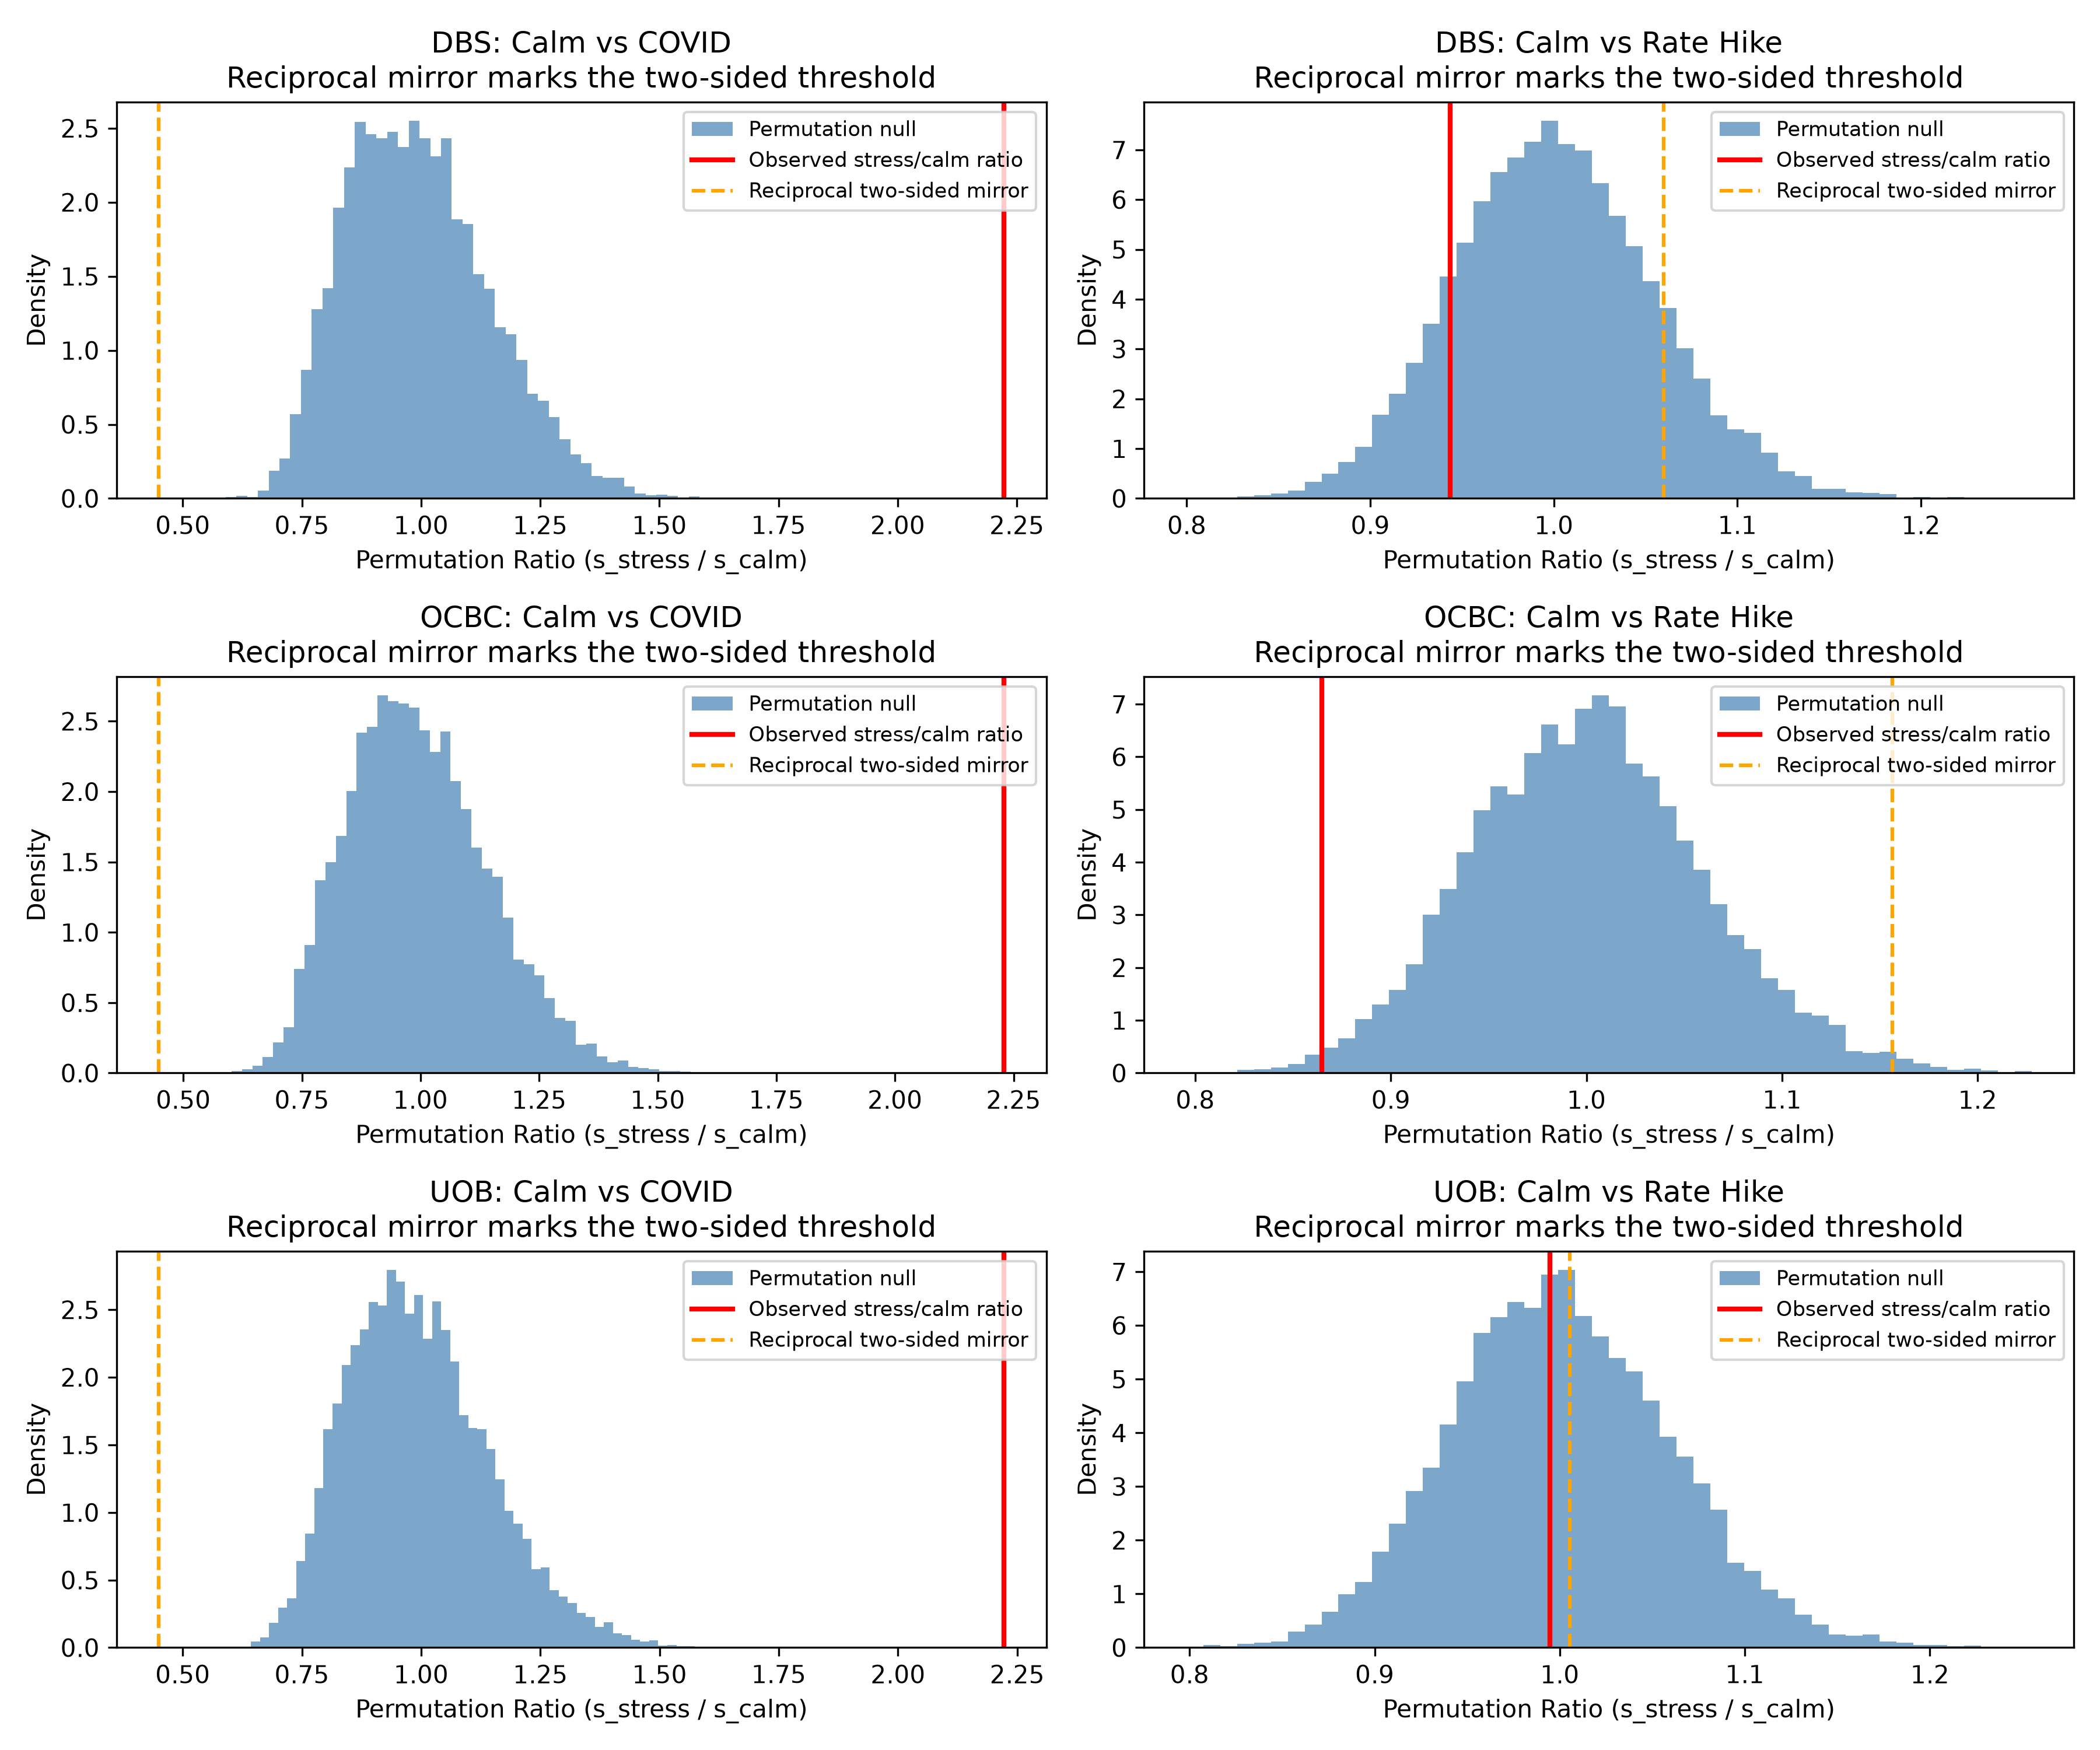

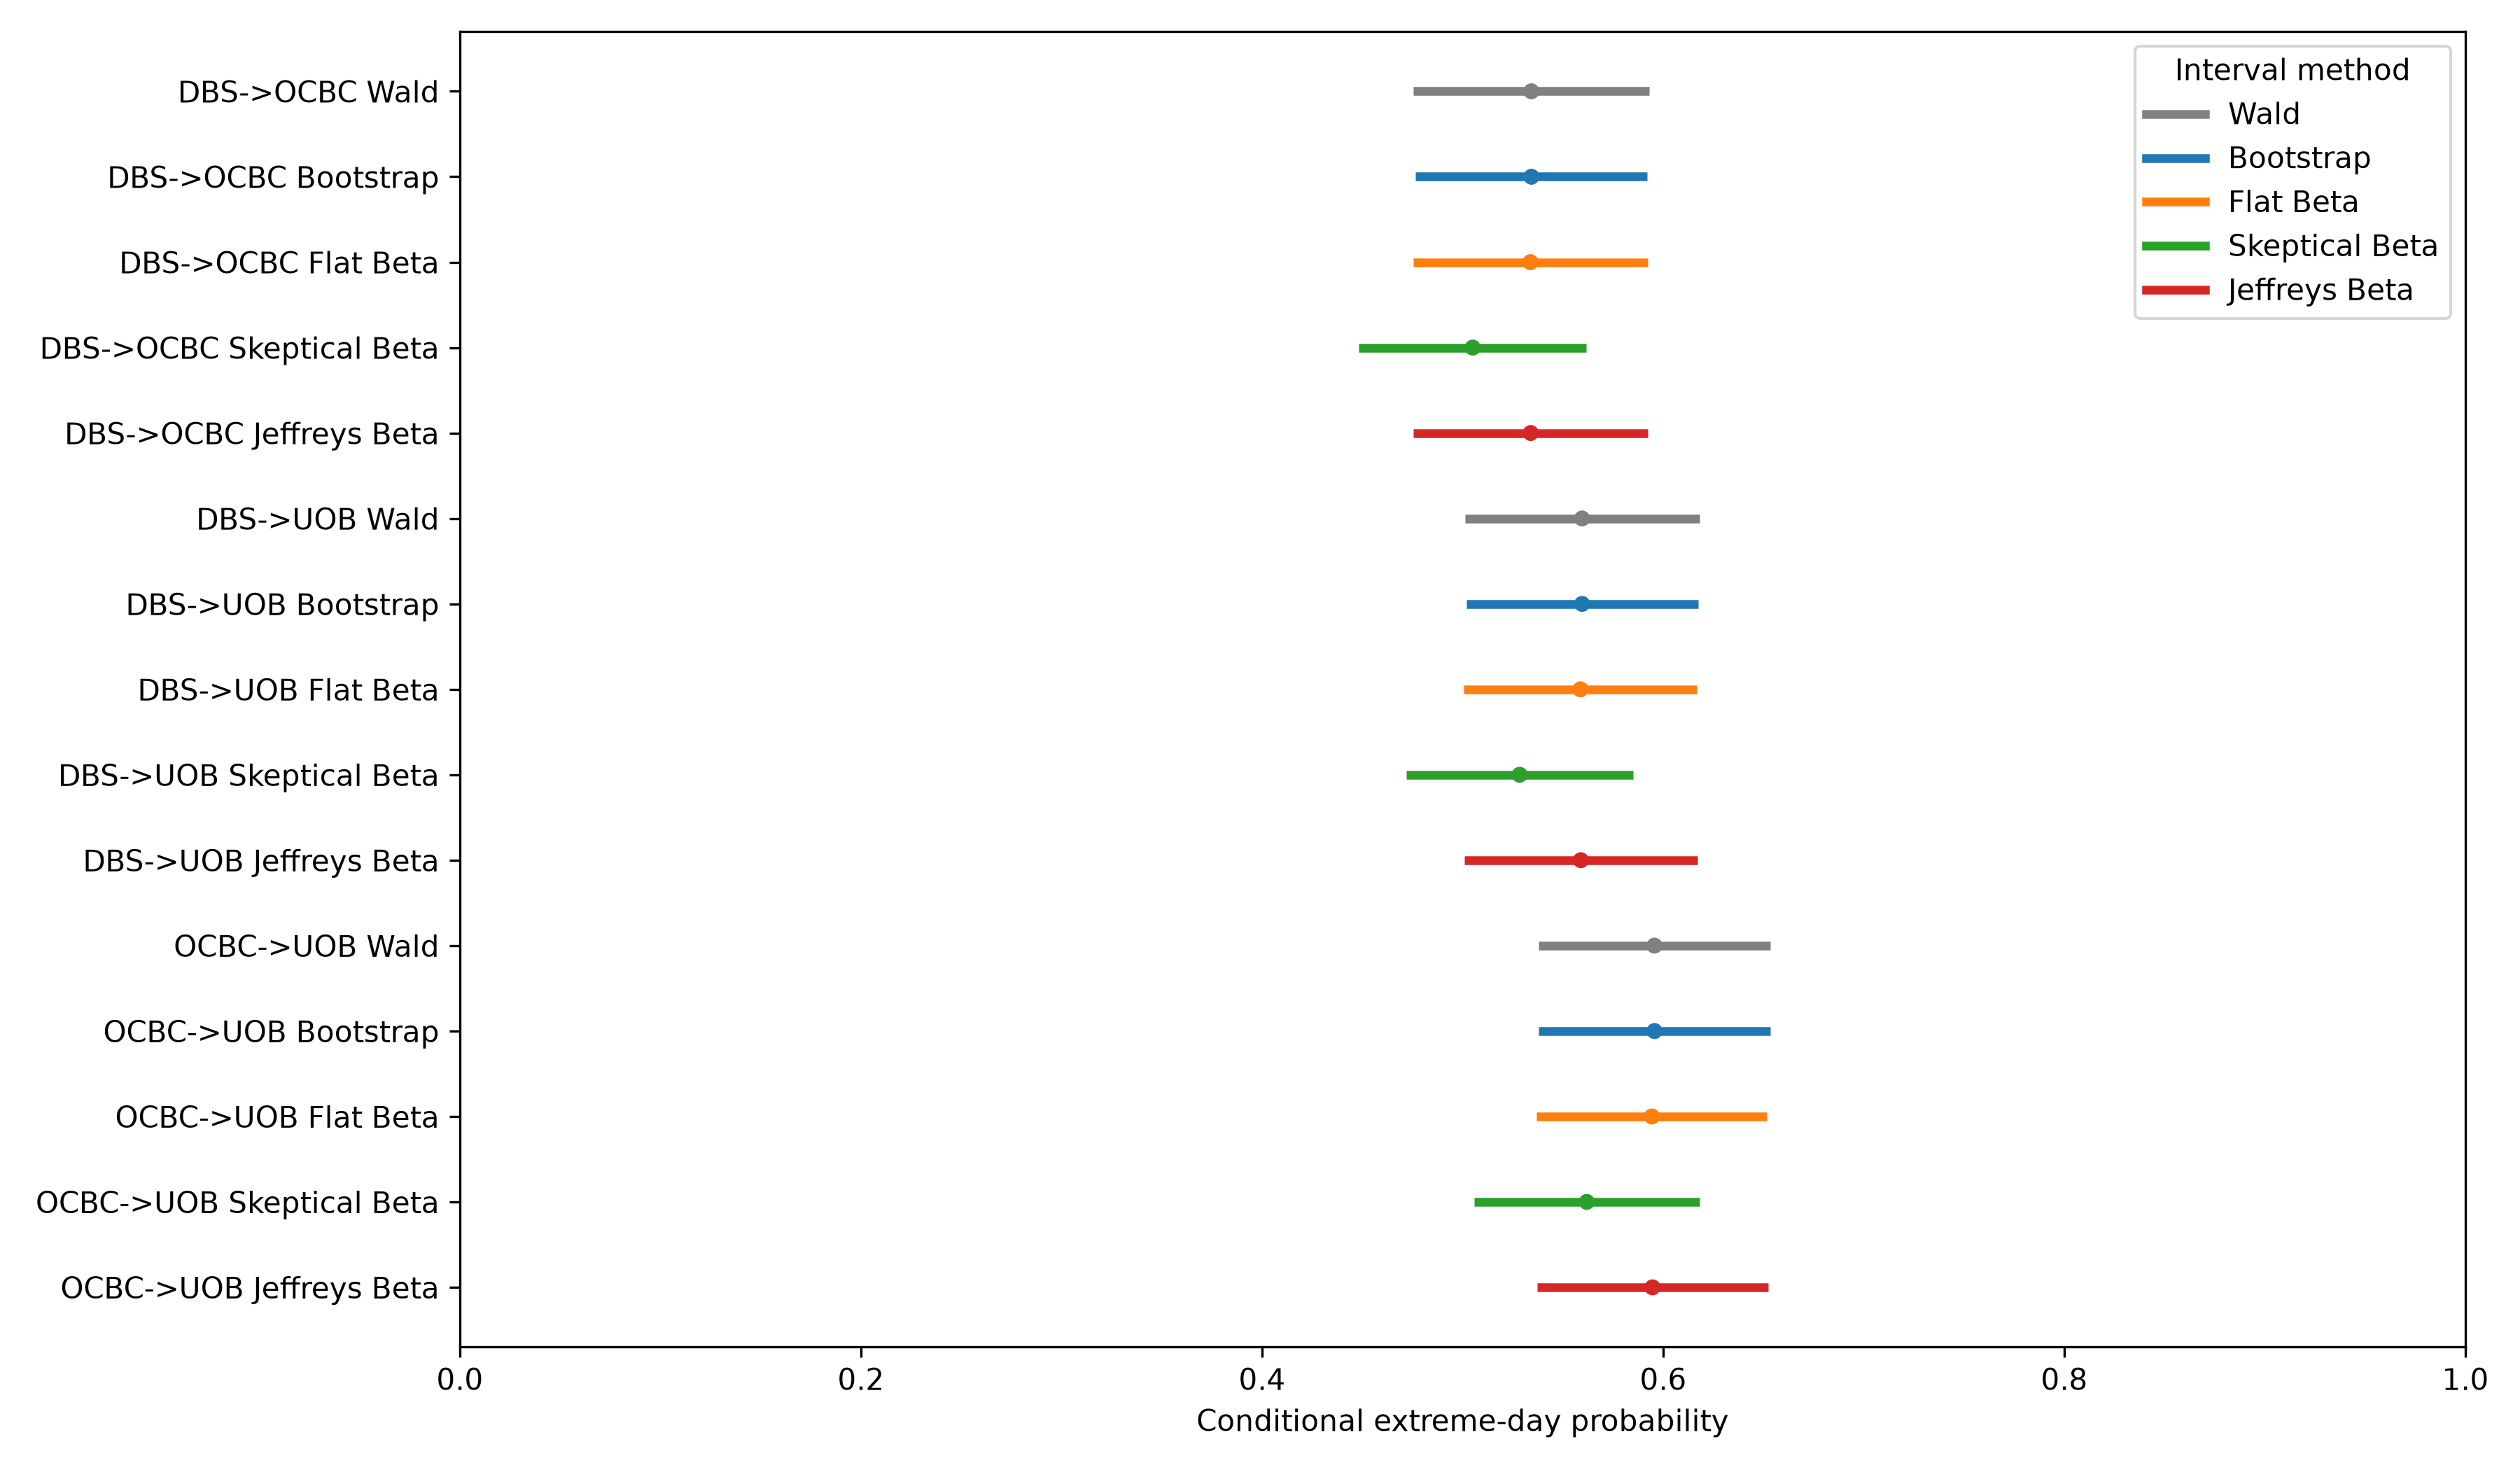

In [5]:
from IPython.display import Image, display
display(Image(filename="outputs/figures/step9_correlation_cis.png"))
display(Image(filename="outputs/figures/step10_permutation_nulls.png"))
display(Image(filename="outputs/figures/step11_bayesian_credible_intervals.png"))

These figures jointly indicate strong linear and rank co-movement, volatility-regime changes, and clustered extreme co-crashes. The Beta-Binomial independence assumption is tenuous because extremes cluster in calendar time.